# Measure I

From `FINDINGS.md`:

> Changes to the real property transfer tax. Yes 150,595, No 163,542. The yes share is 47.9 percent. No leads by 12,947 votes.
>
> Precinct shares run from 35.1 percent to 48.9 percent to 60.8 percent. The yes vote is stronger in the center and the east, in the same parts of the city as Measure B, a few points lower. District 9 is 58.9 percent yes and District 5 is 57.6 percent. District 6 is 50.7 percent and District 10 is 50.6 percent. District 2 is 37.1 percent, District 7 is 40.4 percent, and District 4 is 43.4 percent. The spread from District 2 to District 9 is 21.8 points.
>
> The yes share rises with the Hispanic share of the precinct (r = 0.50) and with the renter share (r = 0.48). It is lower where the share of households at $150,000 or more is higher (r = −0.49). The same three characteristics move with Measure B.

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## Citywide result

In [2]:
city = sf.citywide(data, "measure_i__yes", "measure_i__no")
city

{'measure_i__yes': 150595,
 'measure_i__no': 163542,
 'share_pct': 47.93927490235152,
 'margin': -12947}

## Precinct and supervisor-district geography

In [3]:
share, votes = sf.two_way(data, "measure_i__yes", "measure_i__no")
enough = data["ballots"] >= sf.MIN_BALLOTS
districts = sf.by_district(data, "measure_i__yes", "measure_i__no")
print("Precinct range, 10th / 50th / 90th percentile:", [round(v, 1) for v in sf.percentile_range(share, enough)])
districts.round(1).to_frame("Yes share, percent")

Precinct range, 10th / 50th / 90th percentile: [np.float64(35.1), np.float64(48.9), np.float64(60.8)]


,"Yes share, percent"
Supervisorial,
1,46.90
2,37.10
3,49.60
4,43.40
5,57.60
6,50.70
7,40.40
8,47.80
9,58.90


In [4]:
check.number("Yes votes", 150595, city["measure_i__yes"], 0)
check.number("No votes", 163542, city["measure_i__no"], 0)
check.number("Yes share, percent", 47.9, city["share_pct"])
check.number("No lead, votes", 12947, -city["margin"], 0)
for name, memo, value in zip(["10th", "50th", "90th"], [35.1, 48.9, 60.8], sf.percentile_range(share, enough)):
    check.number(f"Precinct share, {name} percentile", memo, value)
check.number("Yes share, District 9", 58.9, districts[9])
check.number("Yes share, District 5", 57.6, districts[5])
check.number("Yes share, District 6", 50.7, districts[6])
check.number("Yes share, District 10", 50.6, districts[10])
check.number("Yes share, District 2", 37.1, districts[2])
check.number("Yes share, District 7", 40.4, districts[7])
check.number("Yes share, District 4", 43.4, districts[4])
check.fact("Highest and lowest district", "District 9 and District 2",
           f"District {districts.idxmax()} and District {districts.idxmin()}",
           (districts.idxmax(), districts.idxmin()) == (9, 2))
check.number("Spread from District 2 to District 9, points", 21.8, districts.max() - districts.min())

## Next to Measure B

In [5]:
b_share, _ = sf.two_way(data, "measure_b__yes", "measure_b__no")
enough = data["ballots"] >= sf.MIN_BALLOTS
side_by_side = pd.DataFrame({"Measure B": sf.by_district(data, "measure_b__yes", "measure_b__no"), "Measure I": districts})
side_by_side["B minus I, points"] = side_by_side["Measure B"] - side_by_side["Measure I"]
print("Precinct correlation of the B and I yes shares:", round(b_share[enough].corr(share[enough]), 2))
side_by_side.round(1)

Precinct correlation of the B and I yes shares: 0.96


,Measure B,Measure I,"B minus I, points"
Supervisorial,,,
1,50.40,46.90,3.50
2,41.00,37.10,3.90
3,53.10,49.60,3.50
4,45.80,43.40,2.40
5,62.10,57.60,4.50
6,53.60,50.70,2.90
7,45.20,40.40,4.80
8,54.00,47.80,6.20
9,64.10,58.90,5.20


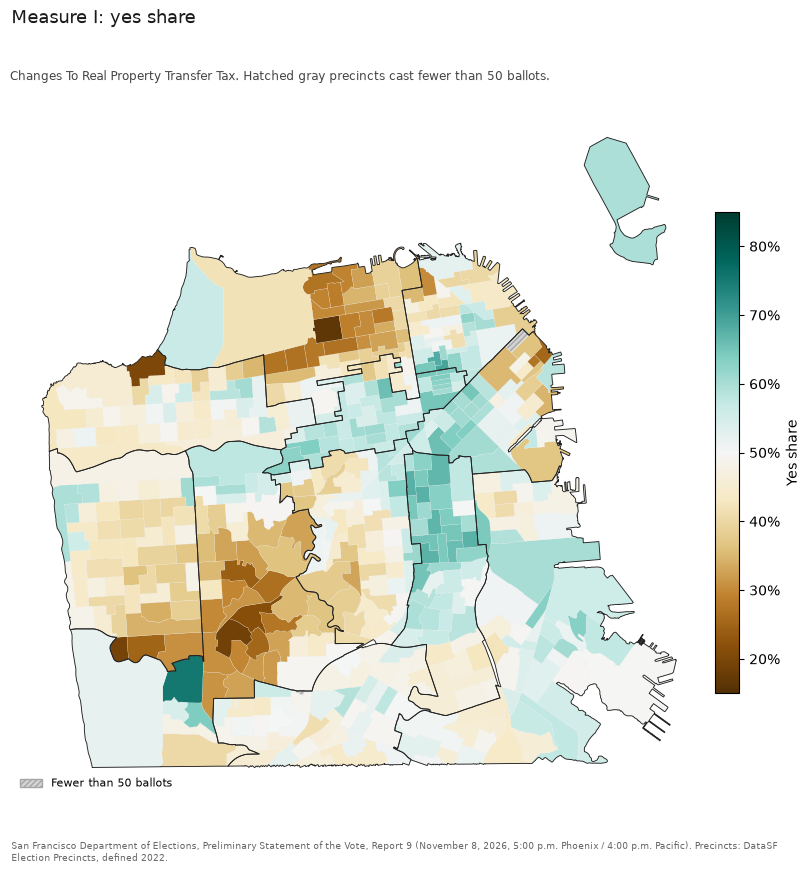

In [6]:
sf.rate_map(data, share, votes, "Measure I: yes share",
            "Changes To Real Property Transfer Tax. Hatched gray precincts cast fewer than 50 ballots.", "Yes share")

## Census comparison

In [7]:
r = sf.census_correlations(data, share, sf.census_frame(data))
display(r.to_frame())
check.number("Correlation with Hispanic", 0.5, r["Hispanic"], 2)
check.number("Correlation with Renters", 0.48, r["Renters"], 2)
check.number("Correlation with Households at $150,000+", -0.49, r["Households at $150,000+"], 2)

,r
Non-Hispanic Asian,-0.09
Non-Hispanic white,-0.30
Hispanic,0.50
Bachelor's degree or higher,-0.36
Renters,0.48
"Households at $150,000+",-0.49
Foreign born,0.13


## Numbers the memo quotes

In [8]:
check.report();

,claim,memo,computed,matches
0,Yes votes,"150,595","150,595",yes
1,No votes,"163,542","163,542",yes
2,"Yes share, percent",47.9,47.9,yes
3,"No lead, votes","12,947","12,947",yes
4,"Precinct share, 10th percentile",35.1,35.1,yes
5,"Precinct share, 50th percentile",48.9,48.9,yes
6,"Precinct share, 90th percentile",60.8,60.8,yes
7,"Yes share, District 9",58.9,58.9,yes
8,"Yes share, District 5",57.6,57.6,yes
9,"Yes share, District 6",50.7,50.7,yes


All 19 numbers checked match the memo.
